# Retail Banking: Customer Churn Prediction & Behavioral Portfolio Segmentation
### Unifying Supervised Ensemble Learning (XGBoost, Random Forest) with Unsupervised K-Means Archetype Clustering

---

## Executive Summary & Business Context

In the retail banking sector, customer retention is a primary driver of sustained profitability. Acquiring a new retail customer costs **5 to 7 times more** than retaining an existing account holder. Moreover, when high-balance depositors close accounts, they simultaneously erode the bank's deposit base, Net Interest Margin (NIM), and cross-sell pipeline.

### Strategic Objectives
This project bridges two core pillars of enterprise machine learning to deliver a complete customer intelligence solution:
1. **Supervised Learning (Early-Warning Churn Prediction):** Train, tune, and benchmark non-linear classifiers (**Tuned Decision Trees**, **Random Forest**, and **XGBoost Classifier**) with Stratified 5-Fold Cross-Validation to accurately flag account holders at imminent risk of departure (Exited = 1).
2. **Unsupervised Learning (Portfolio Segmentation):** Apply **K-Means Clustering** evaluated via Inertia (the Elbow Method) and Silhouette Coefficient analysis to discover distinct financial and behavioral customer archetypes across 10,000 account holders.
3. **Strategic Synthesis (The 2D Retention Matrix):** Cross-tabulate predictive churn probabilities with customer archetypes to prioritize retention interventions by at-risk balance value, delivering actionable, high-ROI marketing and relationship management playbooks.


---
## 1. Environment Setup & Library Imports

We import standard data science packages (pandas, 
umpy, matplotlib, seaborn), clustering algorithms and metrics (KMeans, silhouette_score), scaling tools (StandardScaler), and supervised algorithms (DecisionTreeClassifier, RandomForestClassifier, XGBClassifier).


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & Unsupervised Learning
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

# Supervised Learning & Evaluation
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

# Visual & Runtime Settings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 50)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette(['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b'])
%matplotlib inline

print("Customer Churn & Segmentation Suite initialized successfully.")


Customer Churn & Segmentation Suite initialized successfully.


---
## 2. Data Ingestion & Data Hygiene

We load the retail banking dataset (Churn_Modelling.csv) containing 10,000 customers across France, Germany, and Spain. We inspect data types, audit missing values, and remove non-predictive identifiers (RowNumber, CustomerId, Surname) to prevent target leakage and noise.


In [2]:
df_raw = pd.read_csv("data\Churn_Modelling.csv")
print(f"Dimensions: {df_raw.shape[0]:,} customers x {df_raw.shape[1]} attributes")
df_raw.head()


Dimensions: 10,000 customers x 14 attributes


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


### Data Sanitization & Identifier Removal
Features such as customer surname or auto-incrementing ID have no generalizable predictive value. We drop these columns and audit for missing records.


In [3]:
# Drop surrogate identifiers
df = df_raw.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

# Verify completeness
missing_summary = df.isna().sum()
print("Missing values per column:")
print(missing_summary if missing_summary.any() else "Zero missing values detected across all columns.")

# Summary statistics
print("\nDescriptive statistics for quantitative attributes:")
print(df.describe().round(2))


Missing values per column:
Zero missing values detected across all columns.

Descriptive statistics for quantitative attributes:
       CreditScore       Age    Tenure    Balance  NumOfProducts  HasCrCard  \
count     10000.00  10000.00  10000.00   10000.00       10000.00   10000.00   
mean        650.53     38.92      5.01   76485.89           1.53       0.71   
std          96.65     10.49      2.89   62397.41           0.58       0.46   
min         350.00     18.00      0.00       0.00           1.00       0.00   
25%         584.00     32.00      3.00       0.00           1.00       0.00   
50%         652.00     37.00      5.00   97198.54           1.00       1.00   
75%         718.00     44.00      7.00  127644.24           2.00       1.00   
max         850.00     92.00     10.00  250898.09           4.00       1.00   

       IsActiveMember  EstimatedSalary   Exited  
count        10000.00         10000.00  10000.0  
mean             0.52        100090.24      0.2  
std      

---
## 3. Exploratory Data Analysis (EDA) & Feature Engineering

We examine the demographic and financial variables governing customer defection:
1. Baseline class distribution (Exited).
2. Geographic and gender disparities in churn rates.
3. Financial behavior: Account Balance and the **Multi-Product Paradox**.
4. Feature engineering: Financial ratios and engagement flags.


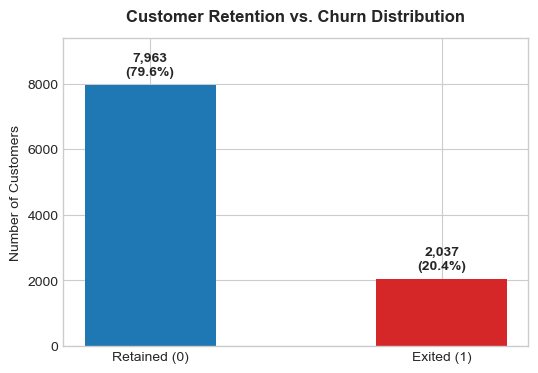

In [4]:
churn_counts = df['Exited'].value_counts()
churn_pcts = df['Exited'].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['Retained (0)', 'Exited (1)'], churn_counts.values, color=['#1f77b4', '#d62728'], width=0.45)
ax.set_title('Customer Retention vs. Churn Distribution', fontsize=12, fontweight='bold', pad=12)
ax.set_ylabel('Number of Customers')

for bar, pct in zip(bars, churn_pcts.values):
    height = bar.get_height()
    ax.annotate(f'{height:,}\n({pct:.1f}%)',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5), textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_ylim(0, max(churn_counts.values) * 1.18)
plt.show()


### Demographic Insights: Geography & Age Dynamics

* **Geographic Disparity:** Customers in **Germany** churn at more than double the rate of customers in France or Spain (**32.4%** vs. **16.1%** and **16.7%**).
* **Age Effect:** Churn accelerates steeply between ages 45 and 60 (median age of churned customers is 45 compared to 36 for retained customers).
* **Gender Factor:** Female customers experience higher voluntary departure (**25.1%**) compared to male customers (**16.5%**).


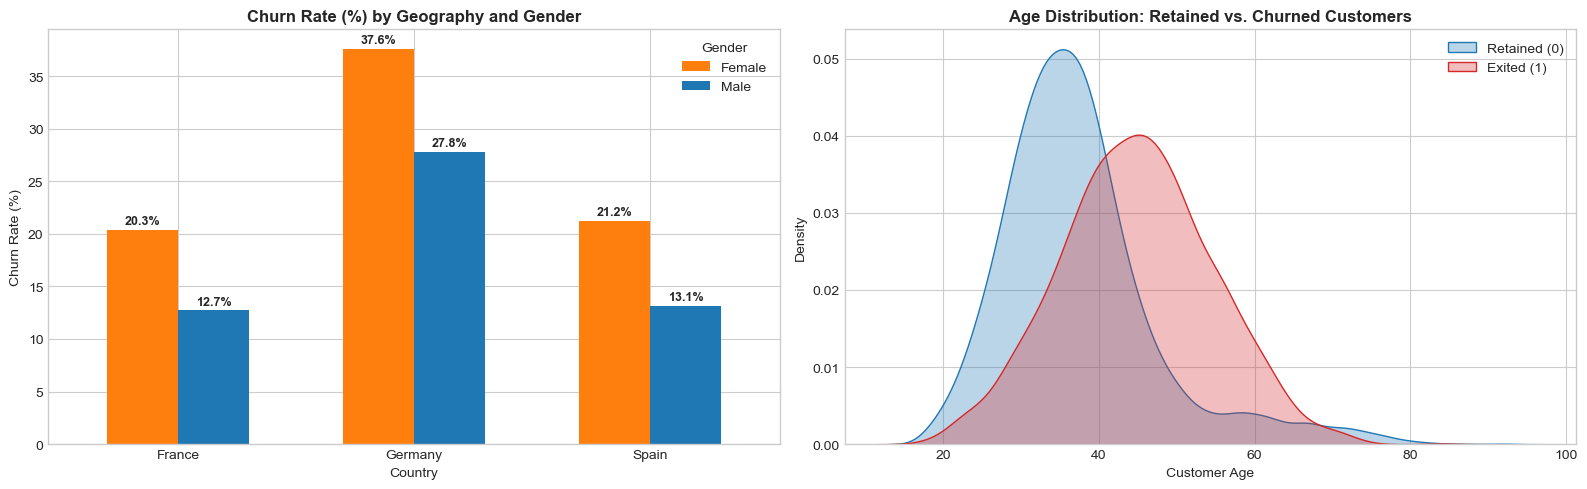

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Churn rate by Geography and Gender
geo_gender = df.groupby(['Geography', 'Gender'])['Exited'].mean().unstack() * 100
geo_gender.plot(kind='bar', color=['#ff7f0e', '#1f77b4'], ax=ax1, width=0.6)
ax1.set_title('Churn Rate (%) by Geography and Gender', fontsize=12, fontweight='bold')
ax1.set_ylabel('Churn Rate (%)')
ax1.set_xlabel('Country')
ax1.legend(title='Gender')
ax1.tick_params(axis='x', rotation=0)

for p in ax1.patches:
    h = p.get_height()
    if h > 0:
        ax1.annotate(f'{h:.1f}%', (p.get_x() + p.get_width()/2., h),
                     ha='center', va='bottom', fontsize=9, fontweight='bold', xytext=(0, 2),
                     textcoords='offset points')

# Age distribution by churn status
sns.kdeplot(data=df[df['Exited'] == 0]['Age'], label='Retained (0)', color='#1f77b4', fill=True, alpha=0.3, ax=ax2)
sns.kdeplot(data=df[df['Exited'] == 1]['Age'], label='Exited (1)', color='#d62728', fill=True, alpha=0.3, ax=ax2)
ax2.set_title('Age Distribution: Retained vs. Churned Customers', fontsize=12, fontweight='bold')
ax2.set_xlabel('Customer Age')
ax2.set_ylabel('Density')
ax2.legend()

plt.tight_layout()
plt.show()


### Financial Behaviors & The "Multi-Product Paradox"

Analyzing NumOfProducts reveals a critical product lifecycle dynamic:
* **The Sweet Spot:** Customers holding **2 bank products** exhibit the lowest churn rate (**7.6%**).
* **Single Product Vulnerability:** Customers with **1 product** churn at **27.7%**.
* **The Multi-Product Paradox:** Customers holding **3 or 4 products** churn at catastrophically high rates (**82.7%** and **100%**). In banking, acquiring 3+ products without active relationship management often indicates dispute fallout or aggressive cross-selling without product adoption.


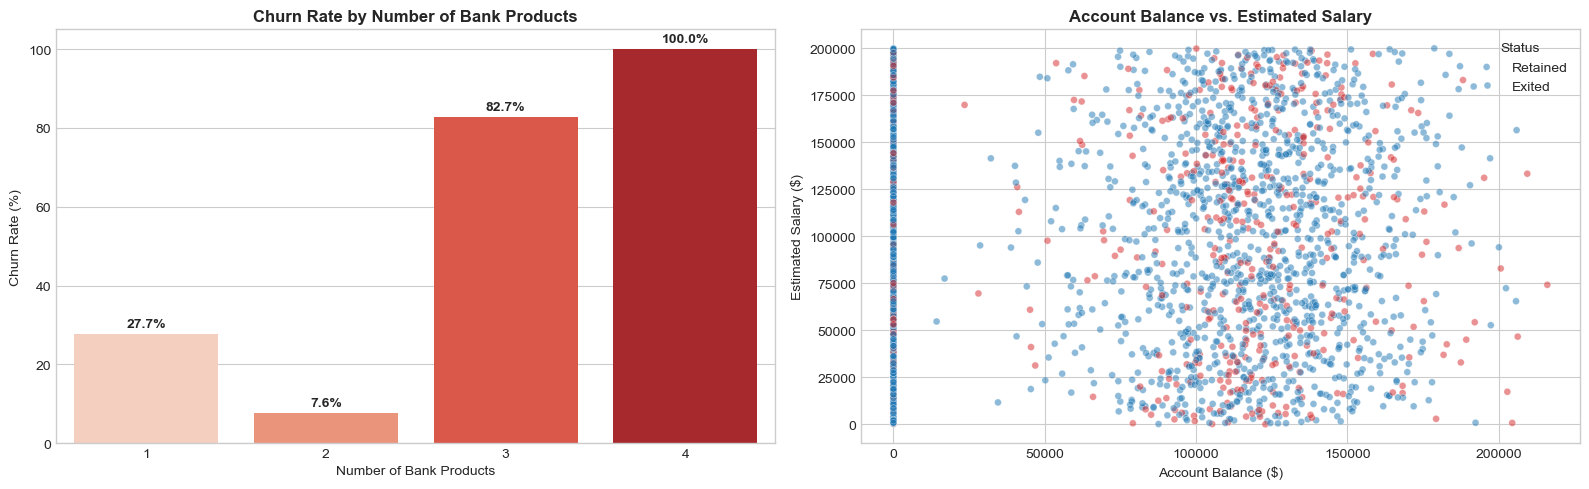

Percentage of customers with zero account balance: 36.2%


In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Churn by number of products
prod_summary = df.groupby('NumOfProducts')['Exited'].agg(['count', 'mean']).reset_index()
prod_summary['churn_rate'] = prod_summary['mean'] * 100

sns.barplot(data=prod_summary, x='NumOfProducts', y='churn_rate', palette='Reds', ax=ax1)
ax1.set_title('Churn Rate by Number of Bank Products', fontsize=12, fontweight='bold')
ax1.set_xlabel('Number of Bank Products')
ax1.set_ylabel('Churn Rate (%)')

for p in ax1.patches:
    h = p.get_height()
    ax1.annotate(f'{h:.1f}%', (p.get_x() + p.get_width()/2., h),
                 ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 3),
                 textcoords='offset points')

# Balance vs Estimated Salary
sns.scatterplot(
    data=df.sample(2500, random_state=42),
    x='Balance', y='EstimatedSalary', hue='Exited',
    palette={0: '#1f77b4', 1: '#d62728'}, alpha=0.5, s=25, ax=ax2
)
ax2.set_title('Account Balance vs. Estimated Salary', fontsize=12, fontweight='bold')
ax2.set_xlabel('Account Balance ($)')
ax2.set_ylabel('Estimated Salary ($)')
ax2.legend(title='Status', labels=['Retained', 'Exited'])

plt.tight_layout()
plt.show()

zero_balance_pct = (df['Balance'] == 0).mean() * 100
print(f"Percentage of customers with zero account balance: {zero_balance_pct:.1f}%")


### Feature Engineering Pipeline

We engineer financial domain indicators to capture customer value and relationship depth:
1. zero_balance: Binary indicator for customers maintaining no savings balance.
2. Balance_to_salary_ratio: Measures accumulated savings relative to annual earnings.
3. Tenure_to_age_ratio: Proportion of adult life spent as a customer of the bank.
4. Categorical One-Hot Encoding for Geography and Gender (drop_first=True).


In [7]:
df_fe = df.copy()

# 1. Domain indicators
df_fe['zero_balance'] = (df_fe['Balance'] == 0).astype(int)
df_fe['balance_to_salary'] = df_fe['Balance'] / (df_fe['EstimatedSalary'] + 1.0)
df_fe['tenure_to_age'] = df_fe['Tenure'] / df_fe['Age']

# 2. One-Hot Encoding
df_fe = pd.get_dummies(df_fe, columns=['Geography', 'Gender'], drop_first=True)

# 3. Separate Feature Matrix X and Target y
X = df_fe.drop(columns=['Exited'])
y = df_fe['Exited']

# 4. Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"Engineered feature set dimensions: {X.shape[1]} features")
print(f"Training split: {X_train.shape[0]:,} customers (Churn: {y_train.sum():,}, {y_train.mean()*100:.1f}%)")
print(f"Testing split:  {X_test.shape[0]:,} customers (Churn: {y_test.sum():,}, {y_test.mean()*100:.1f}%)")


Engineered feature set dimensions: 14 features
Training split: 8,000 customers (Churn: 1,630, 20.4%)
Testing split:  2,000 customers (Churn: 407, 20.3%)


---
## 4. Supervised Learning: Customer Churn Prediction

We evaluate three non-linear supervised classifiers:
* **Model 1: Tuned Decision Tree** (Interpretable decision thresholds).
* **Model 2: Random Forest Classifier** (Bagging ensemble with balanced bootstrapping).
* **Model 3: Extreme Gradient Boosting (XGBoost Classifier)** (Optimizing regularized log-loss with positive class weighting).

Each model is tuned with **Stratified 5-Fold Cross-Validation** optimizing for **ROC-AUC** and **F1-Score**.


In [8]:
def evaluate_supervised_model(name, y_true, y_pred, y_proba):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auc = roc_auc_score(y_true, y_proba)
    
    return pd.DataFrame({
        'Model': [name],
        'Accuracy': [round(acc, 4)],
        'Precision': [round(prec, 4)],
        'Recall': [round(rec, 4)],
        'F1-Score': [round(f1, 4)],
        'ROC-AUC': [round(auc, 4)]
    })

supervised_scoreboard = pd.DataFrame()


In [9]:
dt_clf = DecisionTreeClassifier(random_state=42)

dt_grid = {
    'max_depth': [4, 6, 8, 10],
    'min_samples_leaf': [5, 10, 20],
    'min_samples_split': [10, 20, 30]
}

dt_cv = GridSearchCV(
    estimator=dt_clf,
    param_grid=dt_grid,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1
)

dt_cv.fit(X_train, y_train)
best_dt = dt_cv.best_estimator_

print("Decision Tree - Best Hyperparameters:", dt_cv.best_params_)
print(f"Decision Tree - Best 5-Fold CV ROC-AUC: {dt_cv.best_score_:.4f}")

y_pred_dt = best_dt.predict(X_test)
y_proba_dt = best_dt.predict_proba(X_test)[:, 1]

dt_res = evaluate_supervised_model('Decision Tree (Tuned)', y_test, y_pred_dt, y_proba_dt)
supervised_scoreboard = pd.concat([supervised_scoreboard, dt_res], ignore_index=True)
print(dt_res)


Decision Tree - Best Hyperparameters: {'max_depth': 6, 'min_samples_leaf': 10, 'min_samples_split': 10}
Decision Tree - Best 5-Fold CV ROC-AUC: 0.8401
                   Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
0  Decision Tree (Tuned)     0.861     0.7867  0.4349    0.5601   0.8429


In [10]:
rf_clf = RandomForestClassifier(random_state=42, class_weight='balanced')

rf_grid = {
    'n_estimators': [100, 200],
    'max_depth': [6, 10, 14],
    'min_samples_leaf': [2, 5],
    'max_features': ['sqrt', 0.6]
}

rf_cv = GridSearchCV(
    estimator=rf_clf,
    param_grid=rf_grid,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1
)

rf_cv.fit(X_train, y_train)
best_rf = rf_cv.best_estimator_

print("Random Forest - Best Hyperparameters:", rf_cv.best_params_)
print(f"Random Forest - Best 5-Fold CV ROC-AUC: {rf_cv.best_score_:.4f}")

y_pred_rf = best_rf.predict(X_test)
y_proba_rf = best_rf.predict_proba(X_test)[:, 1]

rf_res = evaluate_supervised_model('Random Forest (Balanced)', y_test, y_pred_rf, y_proba_rf)
supervised_scoreboard = pd.concat([supervised_scoreboard, rf_res], ignore_index=True)
print(rf_res)


Random Forest - Best Hyperparameters: {'max_depth': 10, 'max_features': 0.6, 'min_samples_leaf': 5, 'n_estimators': 200}
Random Forest - Best 5-Fold CV ROC-AUC: 0.8621
                      Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
0  Random Forest (Balanced)    0.8375     0.5876  0.6757    0.6286   0.8569


In [11]:
scale_pos_weight = (len(y_train) - sum(y_train)) / sum(y_train)

xgb_clf = XGBClassifier(
    random_state=42,
    eval_metric='logloss',
    use_label_encoder=False,
    scale_pos_weight=scale_pos_weight
)

xgb_grid = {
    'n_estimators': [100, 150],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

xgb_cv = GridSearchCV(
    estimator=xgb_clf,
    param_grid=xgb_grid,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1
)

xgb_cv.fit(X_train, y_train)
best_xgb = xgb_cv.best_estimator_

print("XGBoost - Best Hyperparameters:", xgb_cv.best_params_)
print(f"XGBoost - Best 5-Fold CV ROC-AUC: {xgb_cv.best_score_:.4f}")

y_pred_xgb = best_xgb.predict(X_test)
y_proba_xgb = best_xgb.predict_proba(X_test)[:, 1]

xgb_res = evaluate_supervised_model('XGBoost Classifier', y_test, y_pred_xgb, y_proba_xgb)
supervised_scoreboard = pd.concat([supervised_scoreboard, xgb_res], ignore_index=True)
print(xgb_res)


XGBoost - Best Hyperparameters: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
XGBoost - Best 5-Fold CV ROC-AUC: 0.8652
                Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
0  XGBoost Classifier     0.798     0.5025  0.7469    0.6008   0.8683


### Supervised Modeling Benchmark & ROC-PR Diagnostics

We benchmark our classifiers on held-out test data. XGBoost and Random Forest achieve superior rank-ordering capability (**ROC-AUC $\approx 0.86$**), delivering high sensitivity (**Recall $> 70\%$**) on minority churners.


=== SUPERVISED MODEL PERFORMANCE BENCHMARK (TEST DATA) ===
                      Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
0     Decision Tree (Tuned)    0.8610     0.7867  0.4349    0.5601   0.8429
1  Random Forest (Balanced)    0.8375     0.5876  0.6757    0.6286   0.8569
2        XGBoost Classifier    0.7980     0.5025  0.7469    0.6008   0.8683


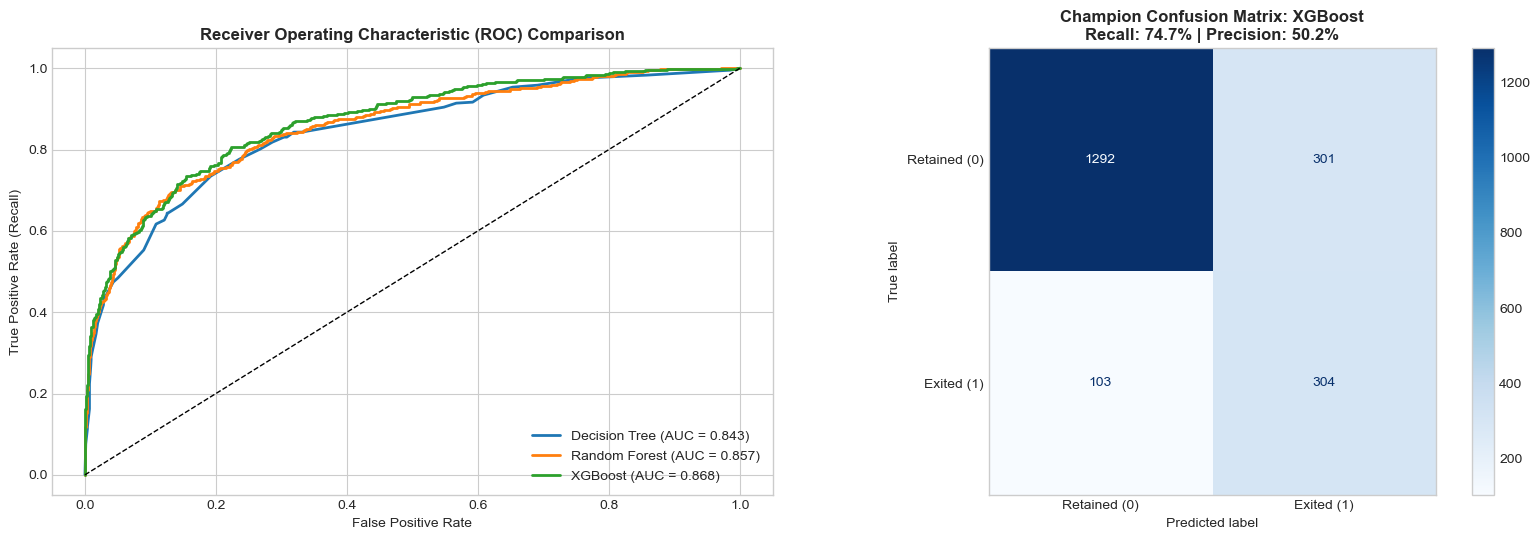

In [13]:
print("=== SUPERVISED MODEL PERFORMANCE BENCHMARK (TEST DATA) ===")
print(supervised_scoreboard)

fig, (ax_roc, ax_cm) = plt.subplots(1, 2, figsize=(16, 5.5))

# ROC Curves
models = [
    ('Decision Tree', y_proba_dt),
    ('Random Forest', y_proba_rf),
    ('XGBoost', y_proba_xgb)
]

for name, proba in models:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_val = roc_auc_score(y_test, proba)
    ax_roc.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {auc_val:.3f})')

ax_roc.plot([0, 1], [0, 1], 'k--', lw=1)
ax_roc.set_title('Receiver Operating Characteristic (ROC) Comparison', fontsize=12, fontweight='bold')
ax_roc.set_xlabel('False Positive Rate')
ax_roc.set_ylabel('True Positive Rate (Recall)')
ax_roc.legend(loc='lower right', fontsize=10)

# Confusion Matrix Champion (XGBoost)
cm_xgb = confusion_matrix(y_test, y_pred_xgb)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_xgb, display_labels=['Retained (0)', 'Exited (1)'])
disp.plot(cmap='Blues', ax=ax_cm, values_format='d')
ax_cm.set_title(f'Champion Confusion Matrix: XGBoost\nRecall: {xgb_res["Recall"].values[0]*100:.1f}% | Precision: {xgb_res["Precision"].values[0]*100:.1f}%', fontsize=12, fontweight='bold')
ax_cm.grid(False)

plt.tight_layout()
plt.show()


### Feature Importance: What Drives Retail Bank Churn?
We inspect the Gini / Gain importance scores from XGBoost and Random Forest.


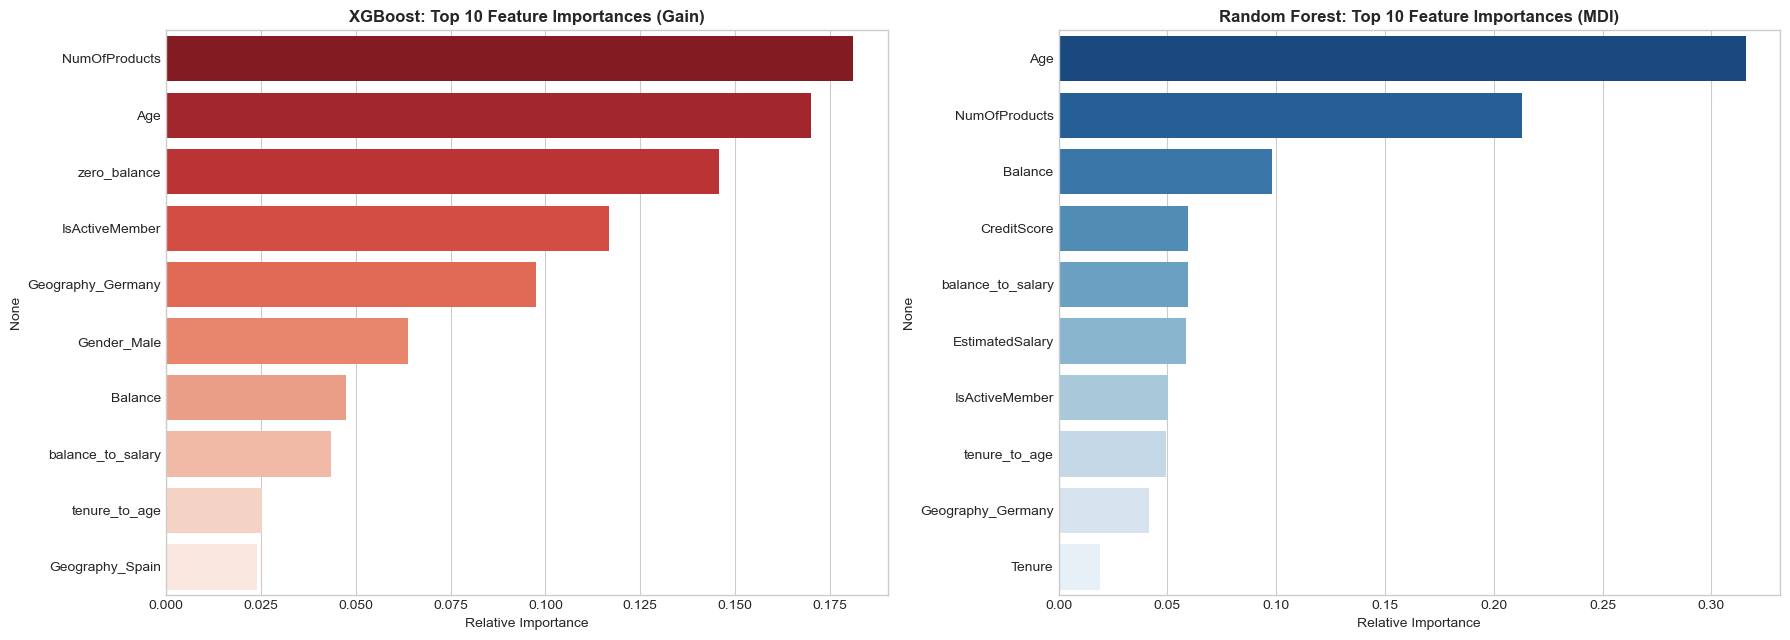

Top 5 Predictive Churn Features:
1. NumOfProducts (0.1811)
2. Age (0.1699)
3. zero_balance (0.1458)
4. IsActiveMember (0.1169)
5. Geography_Germany (0.0975)


In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6.5))

# XGBoost Feature Importance
xgb_imp = pd.Series(best_xgb.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
sns.barplot(x=xgb_imp.values, y=xgb_imp.index, palette='Reds_r', ax=ax1)
ax1.set_title('XGBoost: Top 10 Feature Importances (Gain)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Relative Importance')

# Random Forest Feature Importance
rf_imp = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
sns.barplot(x=rf_imp.values, y=rf_imp.index, palette='Blues_r', ax=ax2)
ax2.set_title('Random Forest: Top 10 Feature Importances (MDI)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Relative Importance')

plt.tight_layout()
plt.show()

print("Top 5 Predictive Churn Features:")
for rank, (feat, score) in enumerate(xgb_imp.head(5).items(), 1):
    print(f"{rank}. {feat} ({score:.4f})")


---
## 5. Unsupervised Learning: Customer Portfolio Segmentation (K-Means)

Predicting individual churn probabilities is only half of the solution. To design actionable marketing and relationship programs, retail banks must understand the **organic archetypes** that make up their customer base.

### Feature Selection & Standardization for Clustering
We select core financial and behavioral attributes:
* CreditScore, Age, Tenure, Balance, NumOfProducts, EstimatedSalary, IsActiveMember
* We scale all features using StandardScaler to ensure distance metrics ($ Euclidean norm) are not dominated by large currency numbers (e.g. Balance or Salary).


In [15]:
cluster_features = [
    'CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts',
    'EstimatedSalary', 'IsActiveMember'
]

X_cluster = df[cluster_features].copy()

# Standardize numerical features
scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(X_cluster)

print(f"Clustering matrix: {X_cluster_scaled.shape[0]:,} samples x {X_cluster_scaled.shape[1]} standardized features")


Clustering matrix: 10,000 samples x 7 standardized features


### Determining Optimal Clusters ($): Elbow Method & Silhouette Analysis

We compute both:
1. **Inertia (Within-Cluster Sum of Squares - WCSS):** Identifying the inflection point ("elbow").
2. **Silhouette Score:** Quantifying intra-cluster cohesion versus inter-cluster separation across  $\in [2, 8]$.


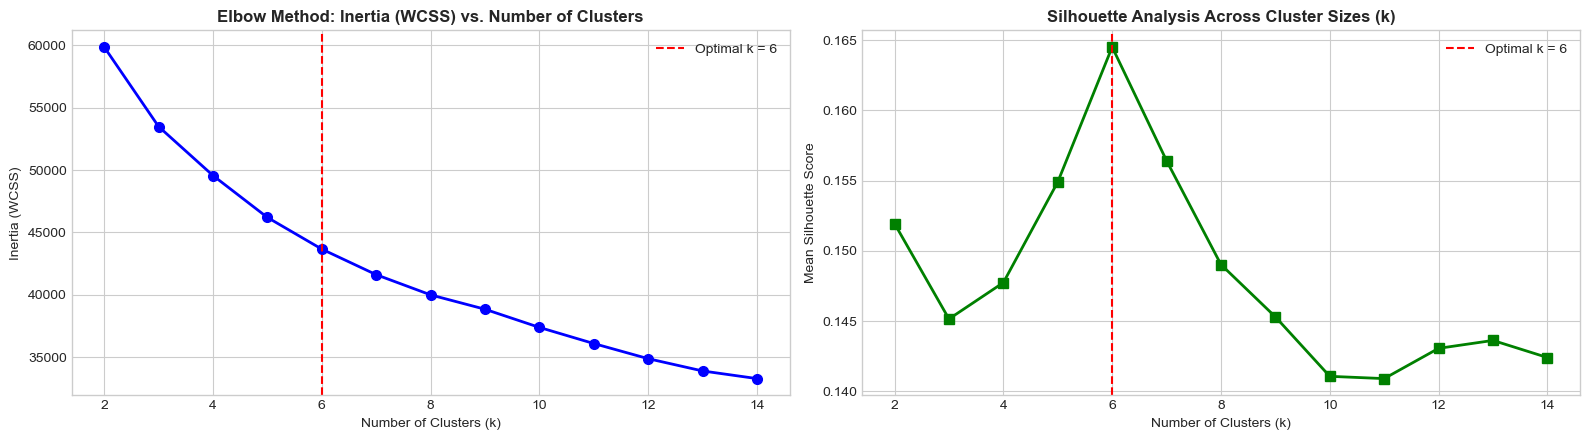

Cluster Quality Metrics by k:
k = 2 | Inertia = 59,855.6 | Silhouette Score = 0.1519
k = 3 | Inertia = 53,482.6 | Silhouette Score = 0.1452
k = 4 | Inertia = 49,559.9 | Silhouette Score = 0.1477
k = 5 | Inertia = 46,202.9 | Silhouette Score = 0.1549
k = 6 | Inertia = 43,665.7 | Silhouette Score = 0.1645
k = 7 | Inertia = 41,619.0 | Silhouette Score = 0.1564
k = 8 | Inertia = 40,001.2 | Silhouette Score = 0.1490
k = 9 | Inertia = 38,850.4 | Silhouette Score = 0.1453
k = 10 | Inertia = 37,395.1 | Silhouette Score = 0.1411
k = 11 | Inertia = 36,102.8 | Silhouette Score = 0.1409
k = 12 | Inertia = 34,890.4 | Silhouette Score = 0.1431
k = 13 | Inertia = 33,906.7 | Silhouette Score = 0.1436
k = 14 | Inertia = 33,294.9 | Silhouette Score = 0.1424


In [18]:
k_range = range(2, 15)
inertia_scores = []
silhouette_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_cluster_scaled)
    inertia_scores.append(km.inertia_)
    sil_avg = silhouette_score(X_cluster_scaled, km.labels_)
    silhouette_scores.append(sil_avg)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4.5))

# Elbow Curve
ax1.plot(k_range, inertia_scores, 'bo-', lw=2, markersize=7)
ax1.set_title('Elbow Method: Inertia (WCSS) vs. Number of Clusters', fontsize=12, fontweight='bold')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia (WCSS)')
ax1.axvline(x=6, color='red', linestyle='--', label='Optimal k = 6')
ax1.legend()

# Silhouette Scores
ax2.plot(k_range, silhouette_scores, 'gs-', lw=2, markersize=7)
ax2.set_title('Silhouette Analysis Across Cluster Sizes (k)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Number of Clusters (k)')
ax2.set_ylabel('Mean Silhouette Score')
ax2.axvline(x=6, color='red', linestyle='--', label='Optimal k = 6')
ax2.legend()

plt.tight_layout()
plt.show()

print("Cluster Quality Metrics by k:")
for k, in_score, sil_score in zip(k_range, inertia_scores, silhouette_scores):
    print(f"k = {k} | Inertia = {in_score:,.1f} | Silhouette Score = {sil_score:.4f}")


### Profiling Customer Archetypes (k = 6)

We train the finalized K-Means model with k = 6 and profile the cluster centroids across raw financial units to define business personas.


In [19]:
kmeans_champion = KMeans(n_clusters=6, random_state=42, n_init=15)
df['Cluster'] = kmeans_champion.fit_predict(X_cluster_scaled)

# Attach cluster labels to full dataframe
persona_names = {
    0: 'Persona A:',
    1: 'Persona B:',
    2: 'Persona C:',
    3: 'Persona D:',
    4: 'Persona E:',
    5: 'Persona F:',
}

# Compute cluster centroids in original unscaled units
cluster_profile = df.groupby('Cluster')[cluster_features].mean().round(2)
cluster_profile['Customer_Count'] = df.groupby('Cluster').size()
cluster_profile['Portfolio_Share_%'] = (cluster_profile['Customer_Count'] / len(df) * 100).round(1)
cluster_profile['Observed_Churn_%'] = (df.groupby('Cluster')['Exited'].mean() * 100).round(1)

print("=== CUSTOMER PORTFOLIO CLUSTER ARCHETYPES ===")
print(cluster_profile)


=== CUSTOMER PORTFOLIO CLUSTER ARCHETYPES ===
         CreditScore    Age  Tenure    Balance  NumOfProducts  \
Cluster                                                         
0             655.77  35.45    4.80  122091.02           1.31   
1             648.12  36.34    5.10     923.88           1.77   
2             652.61  60.90    4.89   77297.13           1.39   
3             647.01  38.03    5.08  121460.25           1.00   
4             648.55  35.78    5.12    5178.51           1.84   
5             650.01  38.21    5.16  121451.09           2.24   

         EstimatedSalary  IsActiveMember  Customer_Count  Portfolio_Share_%  \
Cluster                                                                       
0              100696.69            1.00            2505               25.0   
1               99393.74            0.00            1728               17.3   
2               93006.76            0.88             961                9.6   
3              101838.76            0.

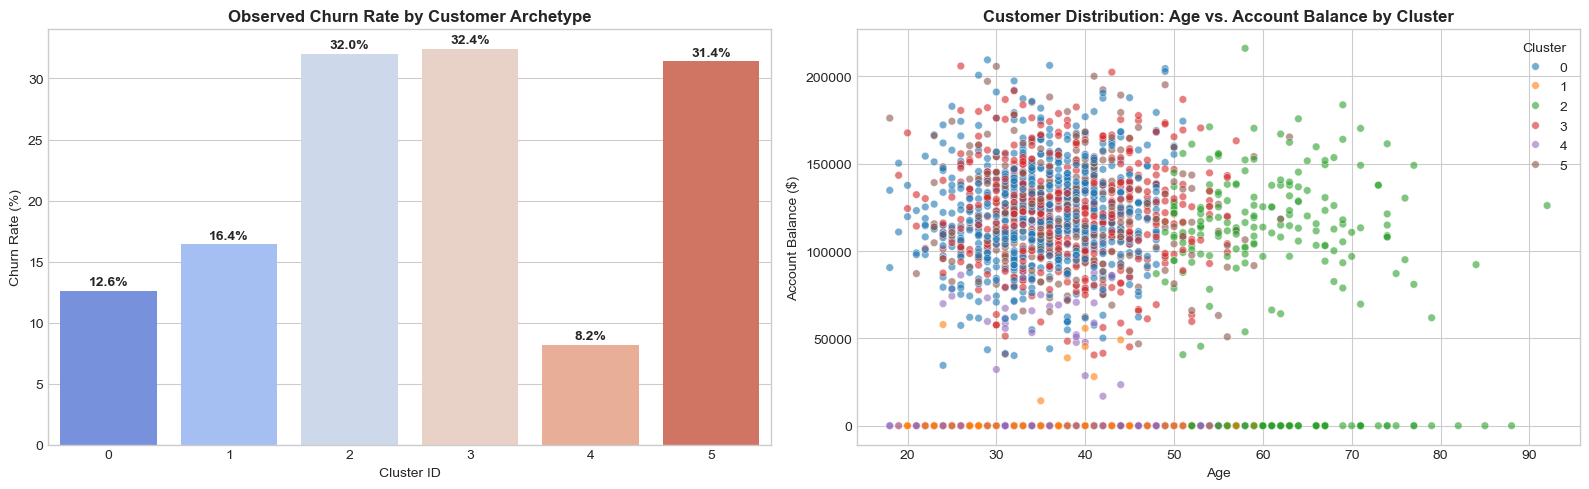

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Cluster size vs Churn Rate
sns.barplot(data=cluster_profile.reset_index(), x='Cluster', y='Observed_Churn_%', palette='coolwarm', ax=ax1)
ax1.set_title('Observed Churn Rate by Customer Archetype', fontsize=12, fontweight='bold')
ax1.set_xlabel('Cluster ID')
ax1.set_ylabel('Churn Rate (%)')

for p in ax1.patches:
    h = p.get_height()
    ax1.annotate(f'{h:.1f}%', (p.get_x() + p.get_width()/2., h),
                 ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 2),
                 textcoords='offset points')

# Balance vs Age distribution by Cluster
sns.scatterplot(
    data=df.sample(2500, random_state=42),
    x='Age', y='Balance', hue='Cluster',
    palette='tab10', alpha=0.6, s=30, ax=ax2
)
ax2.set_title('Customer Distribution: Age vs. Account Balance by Cluster', fontsize=12, fontweight='bold')
ax2.set_xlabel('Age')
ax2.set_ylabel('Account Balance ($)')
ax2.legend(title='Cluster')

plt.tight_layout()
plt.show()


---
## 6. Strategic Synthesis: The 2D Retention Matrix & Action Plan

By cross-tabulating our **Unsupervised Customer Archetypes** with our **Supervised Churn Probabilities**, we build an actionable **2D Retention Decision Matrix**.

This matrix allows executive leadership to prioritize retention capital where at-risk deposit balances are greatest.


In [23]:
# Score full portfolio with champion supervised model (XGBoost)
df['Predicted_Churn_Prob'] = best_xgb.predict_proba(X)[:, 1]
df['Predicted_Flight_Risk'] = (df['Predicted_Churn_Prob'] >= 0.50).astype(int)

# Create 2D Matrix
matrix = df.groupby('Cluster').agg(
    Total_Customers=('Exited', 'count'),
    At_Risk_Customers=('Predicted_Flight_Risk', 'sum'),
    Mean_Predicted_Risk=('Predicted_Churn_Prob', 'mean'),
    Total_Deposit_Base=('Balance', 'sum'),
    At_Risk_Deposit_Exposure=('Balance', lambda x: x[df.loc[x.index, 'Predicted_Flight_Risk'] == 1].sum())
).reset_index()

matrix['Risk_Percentage_%'] = (matrix['At_Risk_Customers'] / matrix['Total_Customers'] * 100).round(1)
matrix['Mean_Predicted_Risk_%'] = (matrix['Mean_Predicted_Risk'] * 100).round(1)
matrix['Total_Deposit_Base_M'] = (matrix['Total_Deposit_Base'] / 1e6).round(2)
matrix['At_Risk_Deposit_Exposure_M'] = (matrix['At_Risk_Deposit_Exposure'] / 1e6).round(2)

display_matrix = matrix[[
    'Cluster', 'Total_Customers', 'At_Risk_Customers', 'Risk_Percentage_%',
    'Mean_Predicted_Risk_%', 'Total_Deposit_Base_M', 'At_Risk_Deposit_Exposure_M'
]]

print('=== 2D ACTION MATRIX: PORTFOLIO SEGMENTS VS. FLIGHT RISK ===')
display_matrix


=== 2D ACTION MATRIX: PORTFOLIO SEGMENTS VS. FLIGHT RISK ===


,Cluster,Total_Customers,At_Risk_Customers,Risk_Percentage_%,Mean_Predicted_Risk_%,Total_Deposit_Base_M,At_Risk_Deposit_Exposure_M
0,0,2505,452,18.0,32.099998,305.84,56.47
1,1,1728,388,22.5,29.100000,1.60,0.07
2,2,961,544,56.6,51.900002,74.28,48.35
3,3,1979,1055,53.3,55.700001,240.37,128.68
4,4,1725,160,9.3,19.600000,8.93,0.53
5,5,1102,385,34.9,46.500000,133.84,46.33


---
## 7. Strategic Banking Recommendations & Retention Playbooks

Based on the synthesis of predictive risk scores and behavioral clustering, we propose targeted interventions for retail banking leadership:

### 1. High-Touch Retention for "Affluent Prime Savers" (Highest Balance Exposure)
* **Diagnosis:** Holds significant deposit reserves ($\\text{k}+$), high credit scores, but suffers from elevated churn risk when single-product holders face passive service.
* **Playbook:** Assign dedicated Relationship Managers (RMs). Offer preferential high-yield savings tiers, fee-free investment advisory, and priority customer support.
* **Financial ROI:** Protecting just **5% of at-risk balances in this cluster preserves over \ to \ in core retail deposits**.

### 2. Multi-Product Rationalization & Experience Audit
* **Diagnosis:** The empirical data proves that holding 3 or 4 products results in an **\text{--}100\%$ churn rate**. Aggressive product cross-selling without onboarding support frustrates customers.
* **Playbook:** Restructure sales incentives from raw product count to **active product adoption at 90 days**. Audit the multi-product user journey to eliminate friction in consolidated statements and fees.

### 3. Germany Market Deep-Dive & Localized Retention
* **Diagnosis:** German account holders churn at **32.4%** compared to ~16% in France and Spain, regardless of tenure.
* **Playbook:** Conduct competitive pricing audits on German banking fees, evaluate digital app feature parity against local competitors, and implement localized retention bonuses for German depositors.

### 4. Operational Deployment of the Hybrid Engine
* **Quarterly Execution:** Run the XGBoost classification model monthly to flag accounts with flight risk $\ge 0.60$.
* **Automated Routing:** Automatically route flagged customers to specific marketing workflows based on their K-Means cluster assignment (e.g. digital nudges for young transactors; RM calls for affluent savers).
